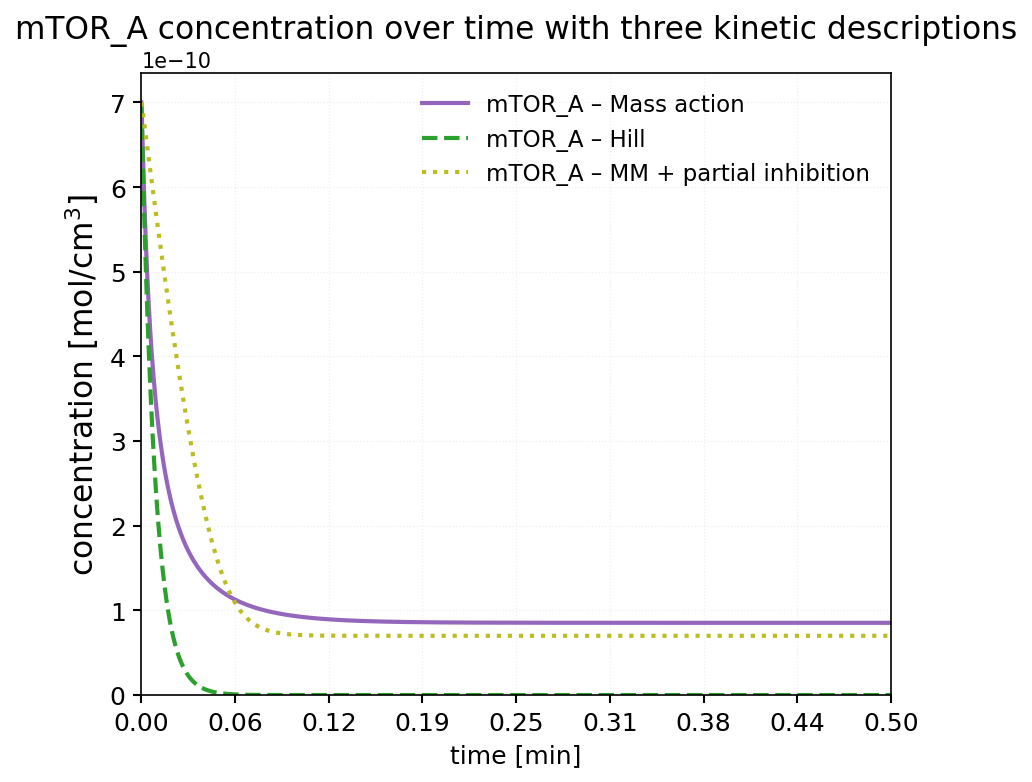

In [6]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# 1. Időskála

early_dense_min = np.linspace(0.0, 0.05, 201)    
later_min       = np.linspace(0.05, 0.5, 200)     

time_short_min = np.unique(np.concatenate([early_dense_min, later_min]))
time_short_sec = time_short_min * 60.0
t_span_short   = (time_short_sec[0], time_short_sec[-1])



# 2. Koncentrációk: mol/cm^3 → mol/L (M)

CM3_TO_L = 1000.0  

RAP0_cm    = 5.0e-8      
MTOR_A0_cm = 7.0e-10     
FKBP0_cm   = 7.0e-10     

RAP0    = RAP0_cm    * CM3_TO_L
MTOR_A0 = MTOR_A0_cm * CM3_TO_L
FKBP0   = FKBP0_cm   * CM3_TO_L


# 3. Tömeghatásos kötési konstansok

kon1  = 1.9e6      # M^-1 s^-1
koff1 = 5.3e-4     # s^-1
kon2  = 2.6e6      # M^-1 s^-1
koff2 = 3.08e-2    # s^-1

KD1 = koff1 / kon1
KD2 = koff2 / kon2  


# 4. MASS ACTION 

def mass_action_rhs(t, y):
    RAP, FKBP, RK, MTOR_A, RKMTOR_A = y

    v1_forward = kon1 * RAP * FKBP
    v1_reverse = koff1 * RK

    
    v2_forward = kon2 * RK * MTOR_A
    v2_reverse = koff2 * RKMTOR_A

    dRAP_dt      = -v1_forward + v1_reverse
    dFKBP_dt     = -v1_forward + v1_reverse
    dRK_dt       =  v1_forward - v1_reverse - v2_forward + v2_reverse
    dMTOR_A_dt   = -v2_forward + v2_reverse
    dRKMTOR_A_dt =  v2_forward - v2_reverse

    return [dRAP_dt, dFKBP_dt, dRK_dt, dMTOR_A_dt, dRKMTOR_A_dt]

y0_mass = [RAP0, FKBP0, 0.0, MTOR_A0, 0.0]

sol_mass = solve_ivp(
    mass_action_rhs,
    t_span_short,
    y0_mass,
    t_eval=time_short_sec,
    method="LSODA",
    rtol=1e-9,
    atol=1e-12
)

RAP_mass    = sol_mass.y[0, :]
MTOR_A_mass = sol_mass.y[3, :]  


# 5. HILL modell 

n_hill      = 1.9
K_Hill      = KD2              
k_deact_max = kon2 * FKBP0     

def hill_rhs(t, y):
    RAP, FKBP, RK, MTOR_A = y

    
    v1_forward = kon1 * RAP * FKBP
    v1_reverse = koff1 * RK

    dRAP_dt  = -v1_forward + v1_reverse
    dFKBP_dt = -v1_forward + v1_reverse
    dRK_dt   =  v1_forward - v1_reverse

   
    hill_factor = RK**n_hill / (K_Hill**n_hill + RK**n_hill)
    dMTOR_A_dt  = -k_deact_max * hill_factor * MTOR_A

    return [dRAP_dt, dFKBP_dt, dRK_dt, dMTOR_A_dt]

y0_hill = [RAP0, FKBP0, 0.0, MTOR_A0]

sol_hill = solve_ivp(
    hill_rhs,
    t_span_short,
    y0_hill,
    t_eval=time_short_sec,
    method="LSODA",
    rtol=1e-9,
    atol=1e-12
)

RAP_hill    = sol_hill.y[0, :]
MTOR_A_hill = sol_hill.y[3, :]  


# 6. MICHAELIS–MENTEN blokk 

kcat_inact = 5.0e-1        
Km_mTOR    = (koff2 + kcat_inact) / kon2  

Ki      = KD2     
f_res   = 0.1    


MTOR_A_res0   = f_res * MTOR_A0          
MTOR_A_sens0  = (1.0 - f_res) * MTOR_A0   

def mm_mtor_rhs(t, y):
    RAP, FKBP, RK, MTOR_A_sens = y

 
    v1_forward = kon1 * RAP * FKBP
    v1_reverse = koff1 * RK

    dRAP_dt  = -v1_forward + v1_reverse
    dFKBP_dt = -v1_forward + v1_reverse
    dRK_dt   =  v1_forward - v1_reverse

 
    I = RK
    A_inakt = (1.0 - f_res) * ( (I / Ki) / (1.0 + (I / Ki)) )

    v_inakt = kcat_inact * RK * A_inakt * MTOR_A_sens / (Km_mTOR + MTOR_A_sens)

    dMTOR_A_sens_dt = -v_inakt

    return [dRAP_dt, dFKBP_dt, dRK_dt, dMTOR_A_sens_dt]

y0_mm_mtor = [RAP0, FKBP0, 0.0, MTOR_A_sens0]


sol_mm_short = solve_ivp(
    mm_mtor_rhs,
    t_span_short,
    y0_mm_mtor,
    t_eval=time_short_sec,
    method="LSODA",
    rtol=1e-9,
    atol=1e-12
)

MTOR_A_sens_short = sol_mm_short.y[3, :]
MTOR_A_mm_tot_short = MTOR_A_res0 + MTOR_A_sens_short  




# 7. Nemnegativitás + visszaváltás mol/cm^3-be

MTOR_A_mass_cm       = np.clip(MTOR_A_mass,         0.0, None) / CM3_TO_L
MTOR_A_hill_cm       = np.clip(MTOR_A_hill,         0.0, None) / CM3_TO_L
MTOR_A_mm_tot_cm     = np.clip(MTOR_A_mm_tot_short, 0.0, None) / CM3_TO_L

# 8. ÁBRA (Rap_big_Zita_friss stílus)

fig, ax = plt.subplots(figsize=(6, 6), dpi=150)
fig.patch.set_facecolor("white")

# Colors aligned with Rap_big_Zita_friss (matplotlib tab colors)
colors = ["#9467bd", "#2ca02c", "#bcbd22"]

ax.plot(time_short_min, MTOR_A_mass_cm,
        label="mTOR_A – Mass action", lw=2, color=colors[0])

ax.plot(time_short_min, MTOR_A_hill_cm,
        label="mTOR_A – Hill",
        linestyle="--", lw=2, color=colors[1])

ax.plot(time_short_min, MTOR_A_mm_tot_cm,
        label="mTOR_A – MM + partial inhibition",
        linestyle=":", lw=2, color=colors[2])

# Match aspect ratio and show 8 x-axis timepoints
x_min = float(time_short_min.min())
x_max = float(time_short_min.max())
ax.set_xlim(x_min, x_max)
ax.set_box_aspect(0.83)
ax.set_ylim(bottom=0)
xticks = np.linspace(x_min, x_max, 9)
ax.set_xticks(xticks)
ax.set_xticklabels([f"{x:.2f}" for x in xticks])

ax.set_xlabel("time [min]", fontsize=12)
ax.set_ylabel(r"concentration [$\mathrm{mol}/\mathrm{cm}^{3}$]", fontsize=15)
ax.set_title("mTOR_A concentration over time with three kinetic descriptions", fontsize=15)

ax.grid(True, which="both", linestyle=":", linewidth=0.6, alpha=0.2)
ax.tick_params(direction="out", length=4, width=1, labelsize=12)

# Legend stays inside, upper-right (as originally)
ax.legend(frameon=False, fontsize=11, loc="upper right")

fig.tight_layout()
plt.show()
